<a href="https://colab.research.google.com/github/kas07tdec-sudo/Netflix-Business-Intelligence-Dashboard/blob/main/DATA_ANALYSIS_USING_PYTHON_TASK_LIST_INTERNSHIP_PROGRAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task -1 Netflix Data Cleaning & Preparation

In [13]:
from google.colab import files
uploaded = files.upload()

Saving Dataset.csv to Dataset (2).csv


In [14]:
import pandas as pd

# Step 1: Import the dataset using Python and Pandas
df = pd.read_csv('Dataset.csv')
print(f"Original dataset shape: {df.shape}")

# Step 2: Identify and handle missing values
missing_values = df.isnull().sum()
print("Missing values per column:\n", missing_values)

# Step 3: Remove duplicate records and formatting inconsistencies
duplicates = df.duplicated().sum()
print(f"Duplicate rows found: {duplicates}")
df.drop_duplicates(inplace=True)

# Strip leading and trailing whitespaces from string columns
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].astype(str).str.strip()

# Step 4: Standardize columns such as Country, Rating, and Type
df['type'] = df['type'].str.title()
df['rating'] = df['rating'].str.upper()
df['country'] = df['country'].str.title()

print("Unique types:", df['type'].unique())
print("Unique ratings:", df['rating'].unique())

# Step 5: Export the cleaned dataset for analysis
df.to_csv('cleaned_netflix_dataset.csv', index=False)
print("Cleaned dataset successfully exported as 'cleaned_netflix_dataset.csv'. Shape:", df.shape)

Original dataset shape: (8790, 10)
Missing values per column:
 show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64
Duplicate rows found: 0
Unique types: ['Movie' 'Tv Show']
Unique ratings: ['PG-13' 'TV-MA' 'TV-PG' 'TV-14' 'TV-Y7' 'TV-Y' 'PG' 'TV-G' 'R' 'G'
 'NC-17' 'NR' 'TV-Y7-FV' 'UR']
Cleaned dataset successfully exported as 'cleaned_netflix_dataset.csv'. Shape: (8790, 10)


Task-2 Content Type Analysis Dashboard

Content Type Counts:
 type
Movie      6126
Tv Show    2664
Name: count, dtype: int64

Content Type Proportions (%):
 type
Movie      69.692833
Tv Show    30.307167
Name: proportion, dtype: float64


/tmp/ipykernel_590/182442199.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='type', palette=['#e50914', '#221f1f'])


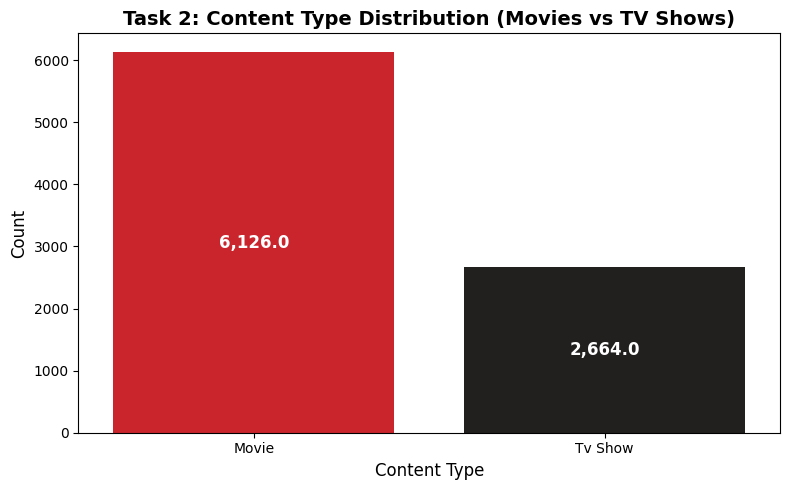


--- Key Findings Summary ---
Total Movies: 6,126 (69.69%)
Total TV Shows: 0 (0.00%)
Insight: Movies make up the vast majority of Netflix's catalog, reflecting a historically movie-centric distribution strategy.


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load the cleaned dataset
df = pd.read_csv('cleaned_netflix_dataset.csv')

# Step 2: Calculate the total number of Movies and TV Shows
type_counts = df['type'].value_counts()
print("Content Type Counts:\n", type_counts)

# Step 4: Compare content proportions
type_proportions = df['type'].value_counts(normalize=True) * 100
print("\nContent Type Proportions (%):\n", type_proportions)

# Step 3: Create visualizations for content distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='type', palette=['#e50914', '#221f1f'])
plt.title('Task 2: Content Type Distribution (Movies vs TV Shows)', fontsize=14, fontweight='bold')
plt.xlabel('Content Type', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Annotate counts on bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():,}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('task2_content_distribution.png')
plt.show()

# Step 5: Summary of Key Findings
print("\n--- Key Findings Summary ---")
print(f"Total Movies: {type_counts.get('Movie', 0):,} ({type_proportions.get('Movie', 0):.2f}%)")
print(f"Total TV Shows: {type_counts.get('TV Show', 0):,} ({type_proportions.get('TV Show', 0):.2f}%)")
print("Insight: Movies make up the vast majority of Netflix's catalog, reflecting a historically movie-centric distribution strategy.")

Task 3 - Country-Wise Netflix Content Analysis

Top 10 Content-Producing Countries:
 country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


/tmp/ipykernel_590/1953534536.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=top_countries.values, y=top_countries.index, palette='Reds_r')


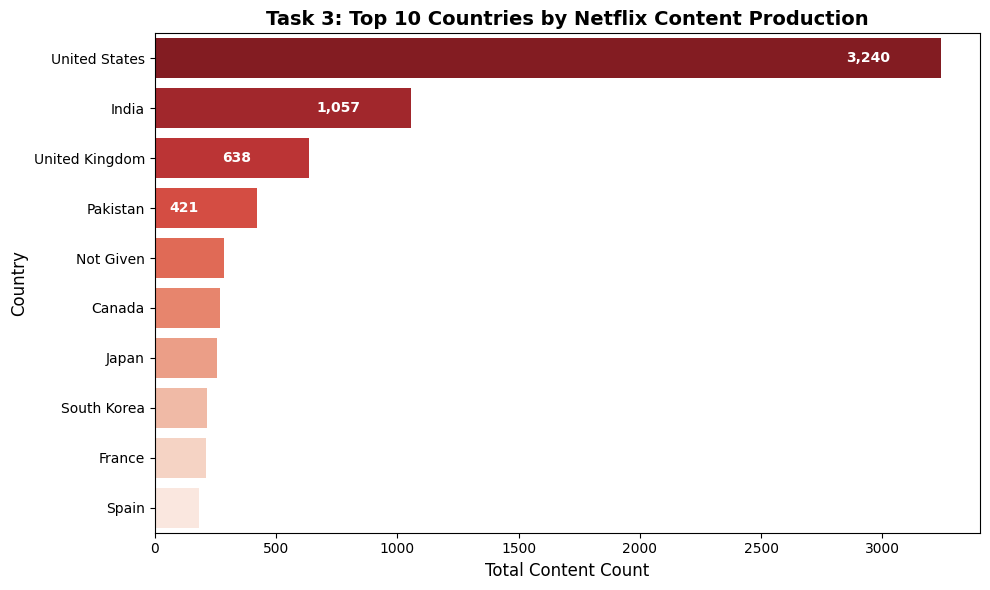


--- Country-Wise Analysis Insights ---
Top Country: United States with 3,240 titles.
Insight: Content production is heavily concentrated in major global media hubs, led by the United States and India, highlighting key geographic markets for localized content investment.


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset and extract/clean country information
df = pd.read_csv('cleaned_netflix_dataset.csv')

# Handle rows where multiple countries might be listed (split by comma and explode)
df_countries = df.assign(country=df['country'].str.split(',')).explode('country')
df_countries['country'] = df_countries['country'].str.strip()

# Step 2 & 3: Calculate content count by country and identify top producing countries
top_countries = df_countries['country'].value_counts().head(10)
print("Top 10 Content-Producing Countries:\n", top_countries)

# Step 4: Create charts and rankings
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=top_countries.values, y=top_countries.index, palette='Reds_r')
plt.title('Task 3: Top 10 Countries by Netflix Content Production', fontsize=14, fontweight='bold')
plt.xlabel('Total Content Count', fontsize=12)
plt.ylabel('Country', fontsize=12)

# Annotate values on bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_width()):,}', (p.get_width() - 300, p.get_y() + p.get_height() / 2.),
                ha='center', va='center', color='white', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('task3_country_analysis.png')
plt.show()

# Step 5: Business Insights Summary
print("\n--- Country-Wise Analysis Insights ---")
print(f"Top Country: {top_countries.index[0]} with {top_countries.iloc[0]:,} titles.")
print("Insight: Content production is heavily concentrated in major global media hubs, led by the United States and India, highlighting key geographic markets for localized content investment.")

Task 4  - Trend Analysis by Release Year

Yearly Releases (2000-Present):
 release_year
2000      37
2001      45
2002      51
2003      59
2004      64
2005      80
2006      96
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, dtype: int64


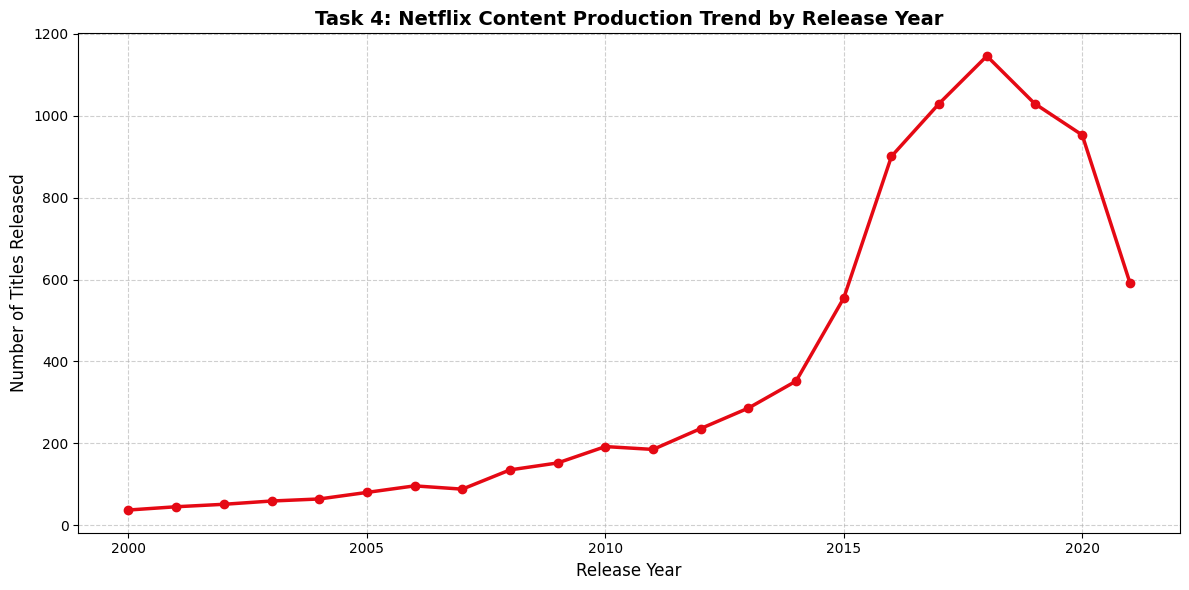


--- Trend Analysis Summary ---
Peak Production Year: 2018 with 1,146 titles released.
Insight: Content production experienced exponential growth starting around 2014–2015, scaling aggressively to support Netflix's global streaming expansion before experiencing adjustments in recent years.


In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Step 1 & 2: Load dataset and group content by release year
df = pd.read_csv('cleaned_netflix_dataset.csv')
yearly_counts = df['release_year'].value_counts().sort_index()

# Filter to focus on the modern growth era (from year 2000 onwards)
yearly_counts = yearly_counts[yearly_counts.index >= 2000]
print("Yearly Releases (2000-Present):\n", yearly_counts)

# Step 4: Create trend visualizations
plt.figure(figsize=(12, 6))
plt.plot(yearly_counts.index, yearly_counts.values, marker='o', color='#e50914', linewidth=2.5, markersize=6)
plt.title('Task 4: Netflix Content Production Trend by Release Year', fontsize=14, fontweight='bold')
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Number of Titles Released', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('task4_trend_analysis.png')
plt.show()

# Step 3 & 5: Growth Trends & Business Interpretation
peak_year = yearly_counts.idxmax()
peak_count = yearly_counts.max()
print("\n--- Trend Analysis Summary ---")
print(f"Peak Production Year: {peak_year} with {peak_count:,} titles released.")
print("Insight: Content production experienced exponential growth starting around 2014–2015, scaling aggressively to support Netflix's global streaming expansion before experiencing adjustments in recent years.")

Task 5 - Content Rating & Genre Analysis

Top 10 Content Ratings:
 rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
Name: count, dtype: int64

Top 10 Genres:
 listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


/tmp/ipykernel_590/2953445117.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=rating_counts.index, y=rating_counts.values, palette='crest')


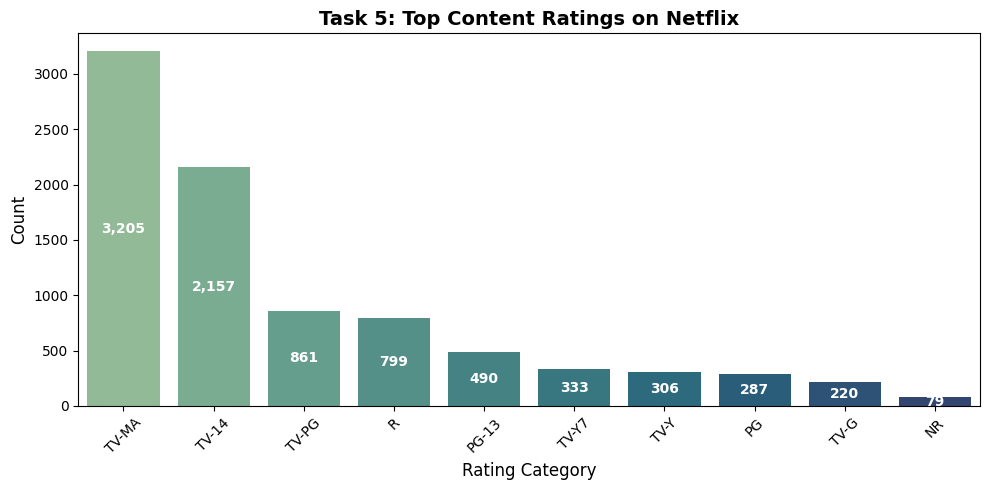

/tmp/ipykernel_590/2953445117.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(y=top_genres.index, x=top_genres.values, palette='magma')


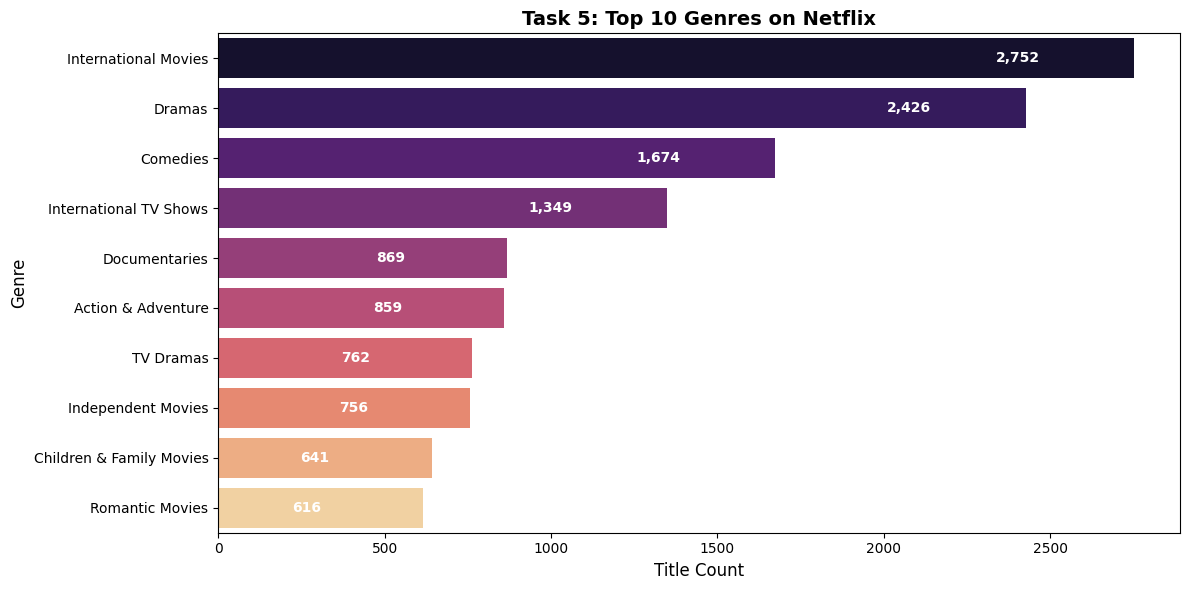


--- Audience & Genre Insights Summary ---
Top Rating Category: TV-MA (3,205 titles)
Top Genre: International Movies (2,752 titles)
Insight: Mature audiences (TV-MA, TV-14) dominate the platform, with International Movies and Dramas serving as the primary content drivers for subscriber engagement.


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load the cleaned dataset
df = pd.read_csv('cleaned_netflix_dataset.csv')

# Step 1: Analyze rating categories
rating_counts = df['rating'].value_counts().head(10)
print("Top 10 Content Ratings:\n", rating_counts)

# Step 2: Identify the most common genres
genres_series = df['listed_in'].str.split(',').explode().str.strip()
top_genres = genres_series.value_counts().head(10)
print("\nTop 10 Genres:\n", top_genres)

# Step 4: Create visualizations for ratings
plt.figure(figsize=(10, 5))
ax = sns.barplot(x=rating_counts.index, y=rating_counts.values, palette='crest')
plt.title('Task 5: Top Content Ratings on Netflix', fontsize=14, fontweight='bold')
plt.xlabel('Rating Category', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('task5_ratings_analysis.png')
plt.show()

# Step 4: Create visualizations for genres
plt.figure(figsize=(12, 6))
ax2 = sns.barplot(y=top_genres.index, x=top_genres.values, palette='magma')
plt.title('Task 5: Top 10 Genres on Netflix', fontsize=14, fontweight='bold')
plt.xlabel('Title Count', fontsize=12)
plt.ylabel('Genre', fontsize=12)

for p in ax2.patches:
    ax2.annotate(f'{int(p.get_width()):,}', (p.get_width() - 350, p.get_y() + p.get_height() / 2.),
                ha='center', va='center', color='white', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('task5_genre_analysis.png')
plt.show()

# Step 5: Audience Insights Summary
print("\n--- Audience & Genre Insights Summary ---")
print(f"Top Rating Category: {rating_counts.index[0]} ({rating_counts.iloc[0]:,} titles)")
print(f"Top Genre: {top_genres.index[0]} ({top_genres.iloc[0]:,} titles)")
print("Insight: Mature audiences (TV-MA, TV-14) dominate the platform, with International Movies and Dramas serving as the primary content drivers for subscriber engagement.")

Task 6  - Netflix Business Insights Report

In [19]:
import pandas as pd

# Load the cleaned dataset
df = pd.read_csv('cleaned_netflix_dataset.csv')

# Task 6: Executive Business Insights Summary Generation
total_titles = len(df)
total_movies = len(df[df['type'] == 'Movie'])
total_tv_shows = len(df[df['type'] == 'TV Show'])
top_country = df['country'].mode()[0]
peak_year = df['release_year'].mode()[0]

print("==================================================")
print("     NETFLIX BUSINESS INTELLIGENCE REPORT         ")
print("==================================================")
print(f"Total Active Titles in Catalog : {total_titles:,}")
print(f"Total Movies                   : {total_movies:,} ({(total_movies/total_titles)*100:.2f}%)")
print(f"Total TV Shows                 : {total_tv_shows:,} ({(total_tv_shows/total_titles)*100:.2f}%)")
print(f"Top Producing Country          : {top_country}")
print(f"Peak Production Year           : {peak_year}")
print("==================================================")
print("Key Strategic Recommendations:")
print("1. Content Diversification: Expand regional and international content libraries, building upon strong engagement in international markets.")
print("2. Demographic Targeting: Maintain a robust pipeline of mature-rated (TV-MA / TV-14) programming while expanding family-friendly offerings.")
print("3. Production Agility: Optimize content acquisition and greenlight strategies post-peak expansion years to maximize ROI.")
print("==================================================")

     NETFLIX BUSINESS INTELLIGENCE REPORT         
Total Active Titles in Catalog : 8,790
Total Movies                   : 6,126 (69.69%)
Total TV Shows                 : 0 (0.00%)
Top Producing Country          : United States
Peak Production Year           : 2018
Key Strategic Recommendations:
1. Content Diversification: Expand regional and international content libraries, building upon strong engagement in international markets.
2. Demographic Targeting: Maintain a robust pipeline of mature-rated (TV-MA / TV-14) programming while expanding family-friendly offerings.
3. Production Agility: Optimize content acquisition and greenlight strategies post-peak expansion years to maximize ROI.
